# CsI(Tl)–SiPM：原始波形尾部、基线/取时与固定三维形状诊断

2026-10-30，承接[PID核心与尾部检查](codex_0001_csi_pid_core_tail.ipynb)。
本轮先固定选取规则，再从原ADC检查极端分位事件，比较基线与定位定义，并检验三维波形形状子空间。
**新增Geant4母事件、原生ADC重放、新实验均为0；不删除尾部事件，不替换正式PID和默认模拟配置。**
全部实验此前已探索，本轮属于固定响应下的内部条件诊断。


In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/waveform_tail_20261030'
def read(p):return json.loads(Path(p).read_text())
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
def fmt(x):return '不可估计' if x is None else f'{x:.3f}'
def nums(x):return ' / '.join(fmt(v) for v in x)
def ci(x):return '不可估计' if x['CI95'] is None else '['+', '.join(fmt(v) for v in x['CI95'])+']'
p=read(OUT/'protocol.json');e=read(OUT/'analysis.json');decision=read(OUT/'decision.json')
examples=read(OUT/'examples.json')['groups']
control_labels={'original':'原定义','recent_baseline':'近期基线','smooth_anchor':'平滑定位','recent_and_smooth':'二者同时'}
model_labels={'frozen':'原冻结','inherited_CV_fit':'连续RC+原谱/CV','spectrum_CV_fit':'连续RC+扩展谱/CV'}
metric='width95_negative_mean_time_ratio'
print('本轮开始时提交:',p['checkpoint_commit'])
print('新增独立母事件 / 原生重放:',p['new_independent_mothers'],p['new_native_replays'])
display(Markdown(decision['conclusion_zh']))

本轮开始时提交: b80bdb374724d7c01379a77497d4b44b80223a2b
新增独立母事件 / 原生重放: 0 0


本轮完成原始ADC极端分位示例、四种基线/取时对照及固定三维波形模式诊断。Am晚段扩展谱（块128）的平均时间95%分位宽度比，原定义为0.872，近期基线与平滑取时同时应用后为0.822；配对变化95%区间为[-0.161, 0.082]，包含0。该统一修正没有解决晚段外侧宽度差异，正式PID和默认模拟参数保持原样。

## 1. 原始ADC和固定示例规则

实验使用run3（⁶⁰Co源）及run12（²⁴¹Am源）既有主带；原ID逐条回查原BIN。
模拟从上一轮已冻结的原生响应数组组装，每个条件内每个母事件只取一份响应。沿用470个不同原母事件，其中Q支持内Co276、Am180个。
原事件/Q/PCA、first60电荷两分目标和母事件折分不变。Am实验主带没有逐事件真值，不能当作纯α；源本身也有γ及衰变电子。

示例只取last20、块128、中间支持Q箱（偶数个箱时取较低中间箱）：Co为箱2，Am为箱1。
每种PID得分分别取最接近其自身加权2.5%、50%、97.5%分位的原事件，同距离按原ID排序。
实验和MC独立选取，未按视觉相似程度配对；36条记录对应32个不同的“组+事件ID”。
图中为未经平滑的ADC减原前128点基线，横轴以原整数t₁₀锚点对齐，不按单条事件缩放幅度。
阴影为近期基线窗口；示例是有限事件展示，不代表总体分布一致，也不凭肉眼判定堆积。


记录 / 不同组内事件: 36 32


|组|得分|目标分位|原ID|原Q箱|原Q|实际标准化得分|
|---|---|---|---|---|---|---|
|run3_last20_data|QDC|0.025|4382|2|283307.250|-1.530|
|run3_last20_data|QDC|0.5|4013|2|299383.750|0.006|
|run3_last20_data|QDC|0.975|3999|2|292313.500|2.196|
|run3_last20_data|negative_mean_time|0.025|4367|2|296379.000|-2.279|
|run3_last20_data|negative_mean_time|0.5|4361|2|293240.250|-0.007|
|run3_last20_data|negative_mean_time|0.975|4688|2|287396.750|1.896|
|run3_last20_data|PCA|0.025|4382|2|283307.250|-2.001|
|run3_last20_data|PCA|0.5|4240|2|304786.750|-0.001|
|run3_last20_data|PCA|0.975|4481|2|295804.000|2.276|
|run3_last20_spectrum_CV_fit|QDC|0.025|7704|2|278444.375|-1.587|
|run3_last20_spectrum_CV_fit|QDC|0.5|1571|2|308614.375|0.490|
|run3_last20_spectrum_CV_fit|QDC|0.975|1732|2|293831.500|2.810|
|run3_last20_spectrum_CV_fit|negative_mean_time|0.025|1010|2|299427.750|-2.462|
|run3_last20_spectrum_CV_fit|negative_mean_time|0.5|1571|2|308614.375|0.115|
|run3_last20_spectrum_CV_fit|negative_mean_time|0.975|1732|2|293831.500|2.340|
|run3_last20_spectrum_CV_fit|PCA|0.025|994|2|275887.125|-2.462|
|run3_last20_spectrum_CV_fit|PCA|0.5|6476|2|291797.375|0.393|
|run3_last20_spectrum_CV_fit|PCA|0.975|6636|2|292622.875|2.610|
|run12_last20_data|QDC|0.025|7397|1|243726.000|-1.440|
|run12_last20_data|QDC|0.5|7439|1|240359.000|0.008|
|run12_last20_data|QDC|0.975|7116|1|258396.500|1.915|
|run12_last20_data|negative_mean_time|0.025|7124|1|259665.500|-2.549|
|run12_last20_data|negative_mean_time|0.5|6261|1|252793.500|-0.191|
|run12_last20_data|negative_mean_time|0.975|7506|1|259734.500|1.928|
|run12_last20_data|PCA|0.025|7462|1|245498.500|-1.200|
|run12_last20_data|PCA|0.5|6764|1|248218.000|-0.003|
|run12_last20_data|PCA|0.975|6347|1|257424.000|1.945|
|run12_last20_spectrum_CV_fit|QDC|0.025|8934|1|263073.375|-1.624|
|run12_last20_spectrum_CV_fit|QDC|0.5|15189|1|266870.250|0.005|
|run12_last20_spectrum_CV_fit|QDC|0.975|21380|1|272988.875|1.918|
|run12_last20_spectrum_CV_fit|negative_mean_time|0.025|4783|1|254164.750|-2.154|
|run12_last20_spectrum_CV_fit|negative_mean_time|0.5|17337|1|239129.250|-0.052|
|run12_last20_spectrum_CV_fit|negative_mean_time|0.975|4718|1|249481.375|1.794|
|run12_last20_spectrum_CV_fit|PCA|0.025|8934|1|263073.375|-1.589|
|run12_last20_spectrum_CV_fit|PCA|0.5|22570|1|261870.625|0.114|
|run12_last20_spectrum_CV_fit|PCA|0.975|14591|1|252590.125|2.050|

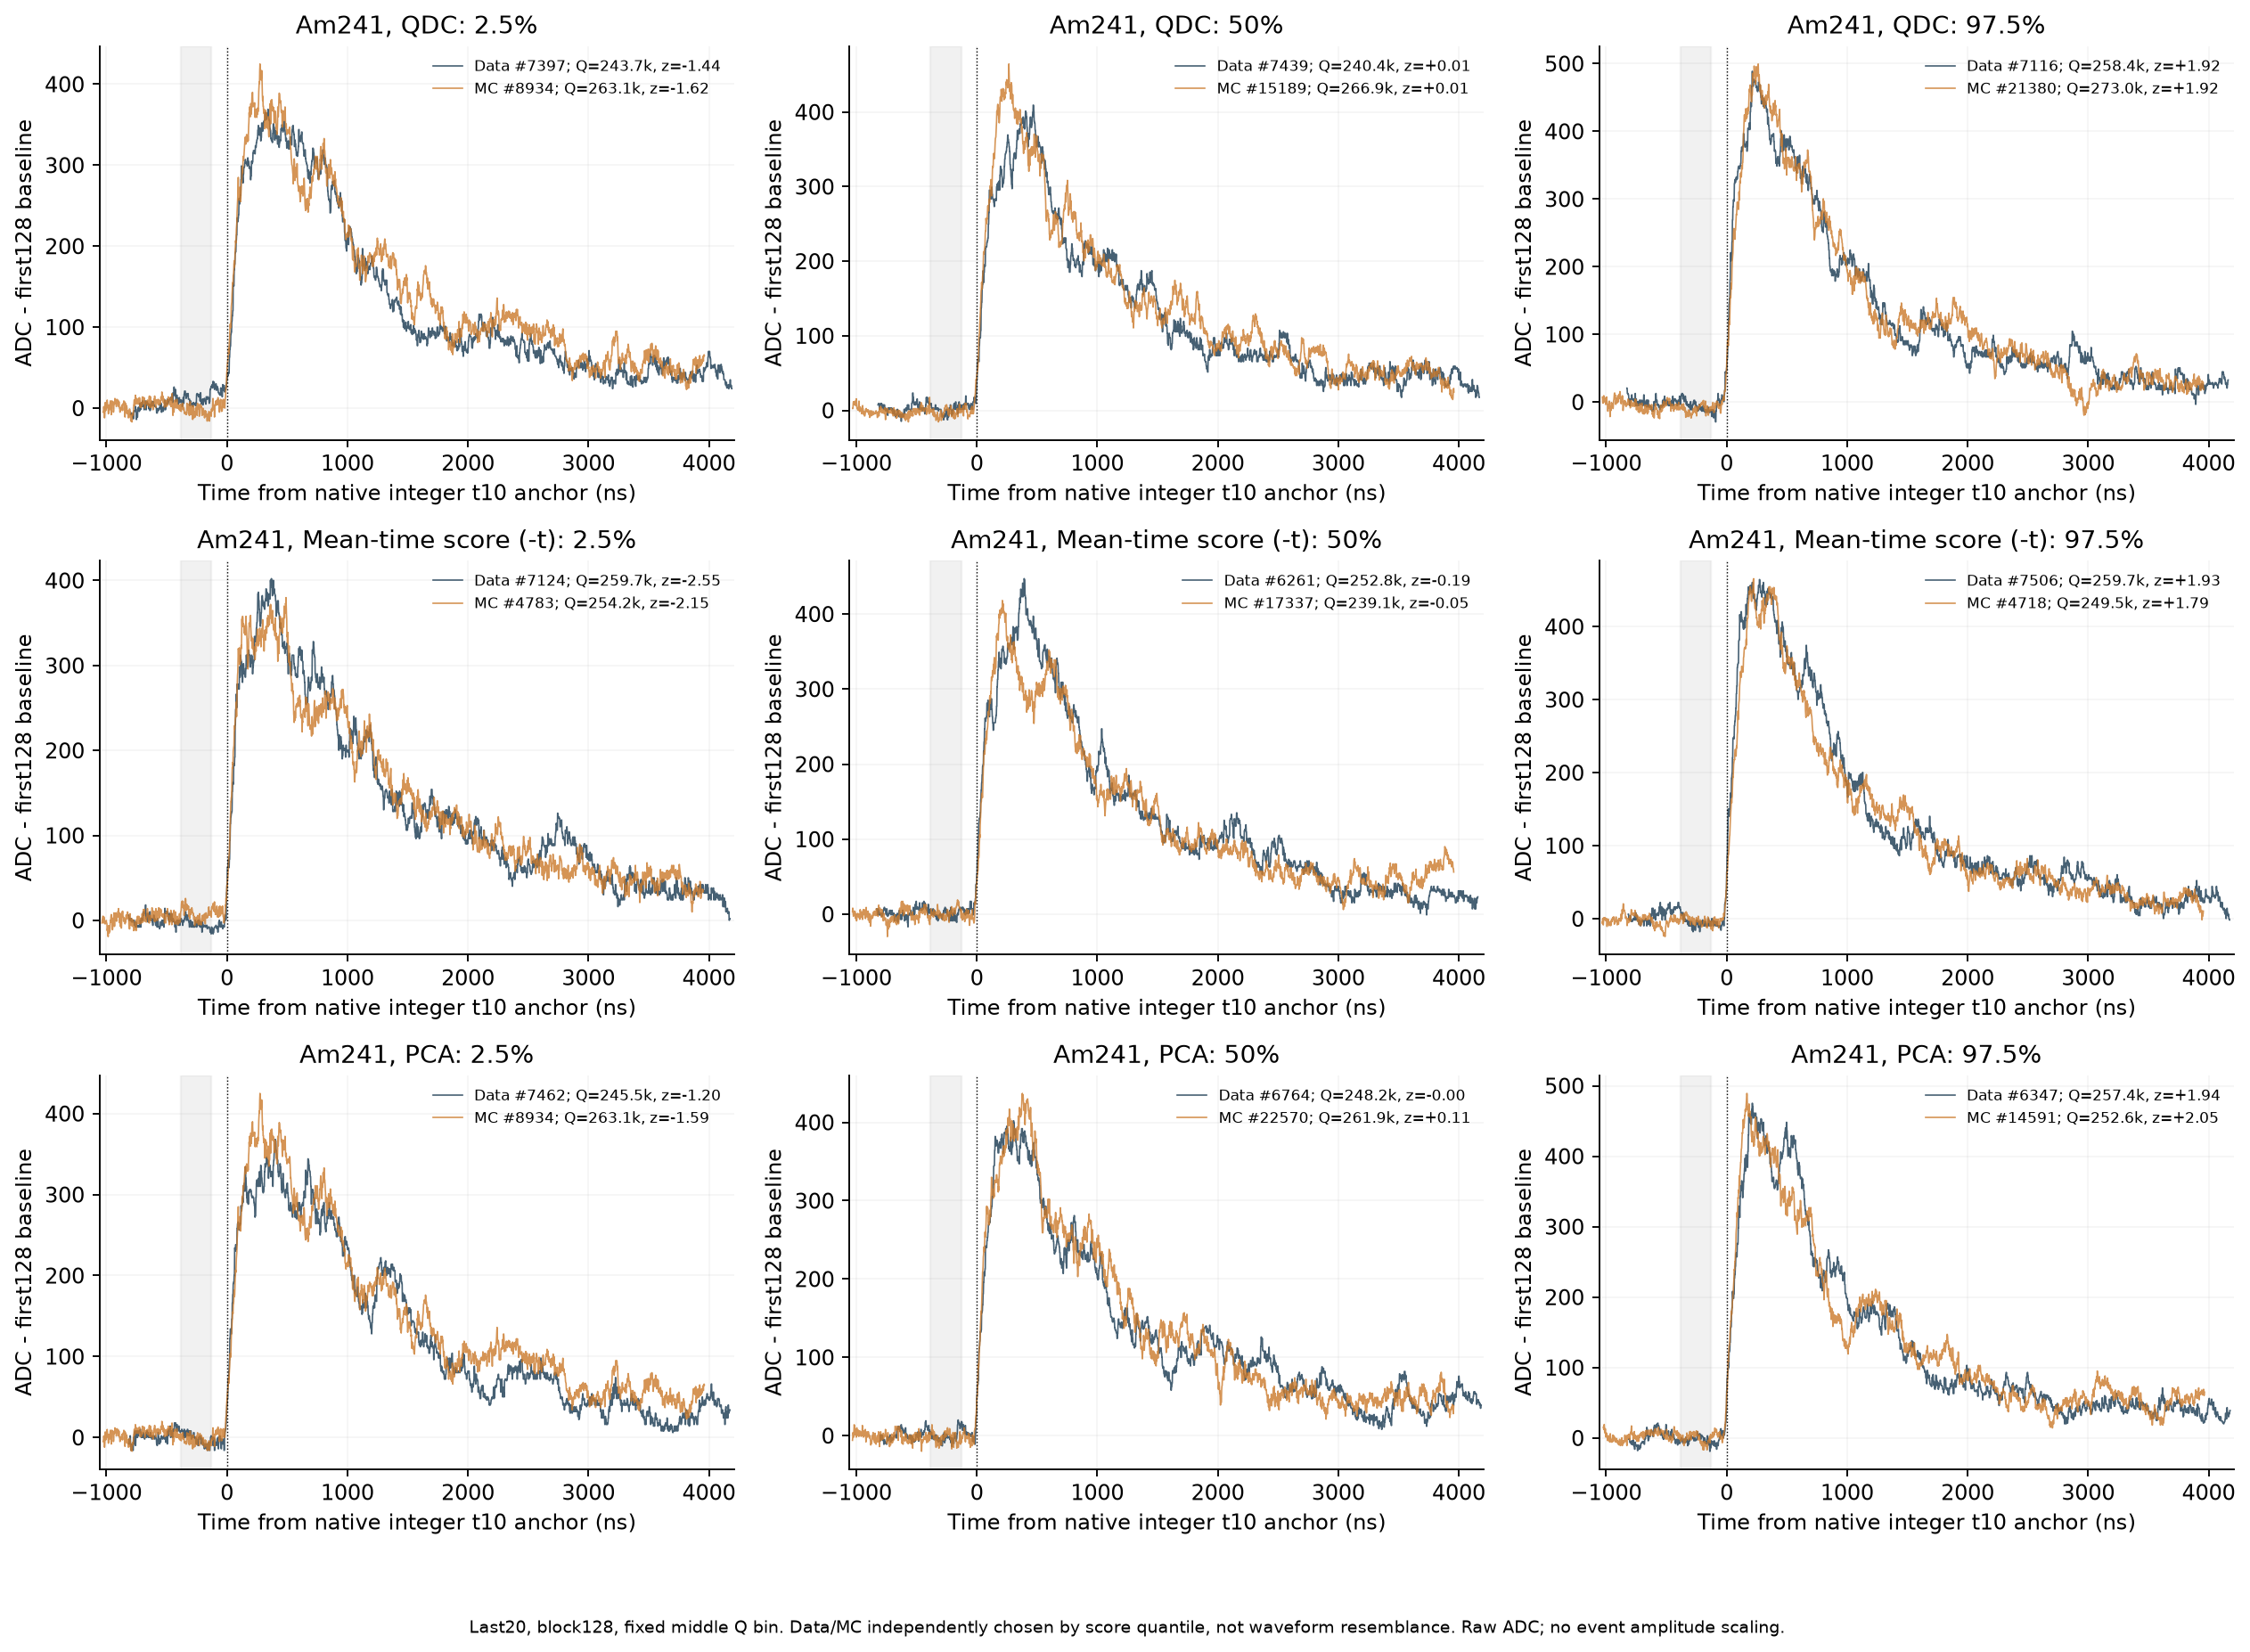

In [2]:
rows=[]
for group,items in examples.items():
    for r in items:
        rows.append([group,r['method'],r['quantile'],r['event_id'],r['Q_bin'],fmt(r['original_Q']),fmt(r['actual_z'])])
display(Markdown(table(['组','得分','目标分位','原ID','原Q箱','原Q','实际标准化得分'],rows)))
print('记录 / 不同组内事件:',decision['example_records'],decision['unique_example_events'])
display(Image(filename=str(OUT/'figures/am_extreme_raw_ADC.png')))

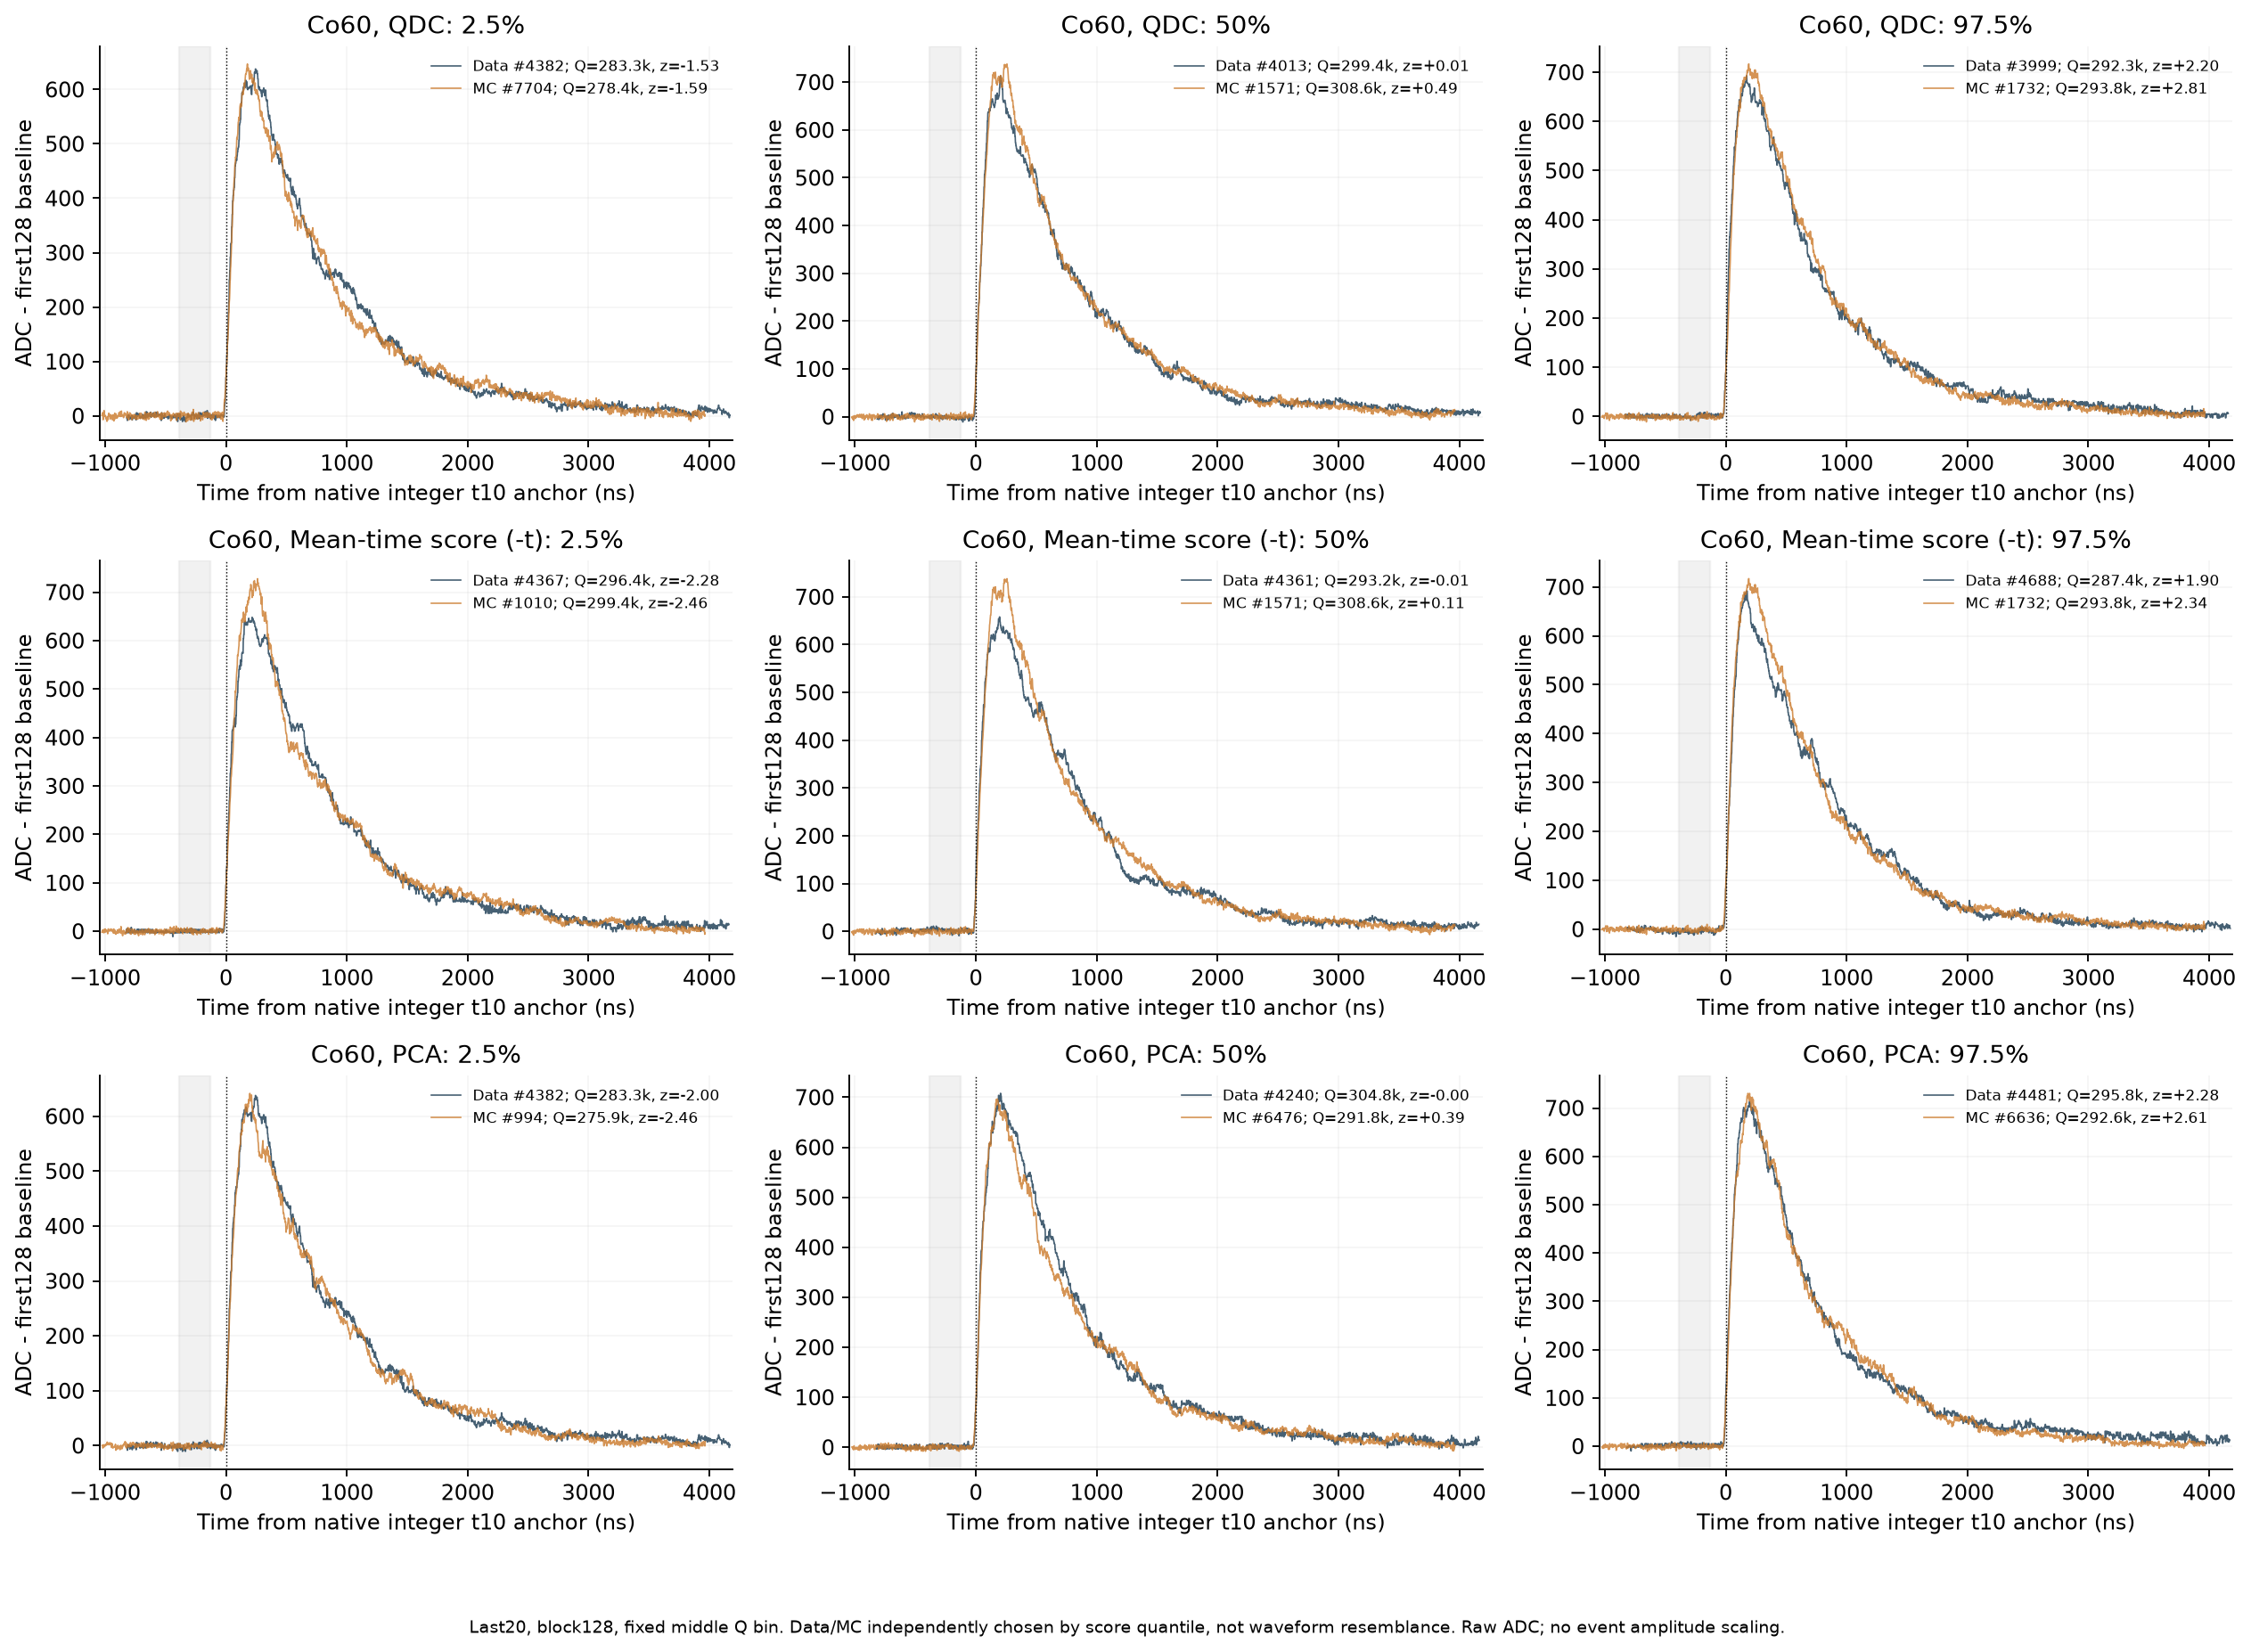

In [3]:
display(Image(filename=str(OUT/'figures/co_extreme_raw_ADC.png')))

## 2. 基线和定位对照

四种定义同时应用于实验和MC，始终在原事件、原Q支持和原权重下计算，不重新选择事件或Q箱。
原定义使用前128点基线与原ADC的t₁₀；近期基线改用原锚点前192至64点（−384至−128 ns）的均值。
平滑定位仅对寻找t₁₀的波形使用11点居中均值，所有积分仍用未平滑ADC；“二者同时”组合这两项。
长门为原定义的−40至3000 ns，短门为−40至500 ns；原PCA始终冻结。

50/80/90/95%宽度是相应中心分位跨度，各Q箱跨度平方等权平均后开根号；SD来自完整箱内协方差。
主分析使用原始事件块128，块64为敏感性检查。512次配对重采样以实验原索引块及完整原MC母事件为单位。
响应、PCA、目标权重、模式和边界均固定；区间不含其拟合不确定度，也没有多重比较校正或等效性检验。


|晚段|块长|定义|平均时间95%宽度MC/实测|条件95%区间|相对原定义配对变化区间|
|---|---|---|---|---|---|
|run3_last20|128|原定义|1.004|[0.867, 1.112]|[0.000, 0.000]|
|run3_last20|128|近期基线|0.989|[0.844, 1.099]|[-0.138, 0.100]|
|run3_last20|128|平滑定位|1.000|[0.864, 1.108]|[-0.027, 0.019]|
|run3_last20|128|二者同时|0.990|[0.852, 1.085]|[-0.137, 0.106]|
|run3_last20|64|原定义|1.029|[0.874, 1.146]|[0.000, 0.000]|
|run3_last20|64|近期基线|1.017|[0.859, 1.134]|[-0.132, 0.112]|
|run3_last20|64|平滑定位|1.019|[0.873, 1.150]|[-0.026, 0.021]|
|run3_last20|64|二者同时|1.007|[0.862, 1.124]|[-0.130, 0.112]|
|run12_last20|128|原定义|0.872|[0.734, 1.104]|[0.000, 0.000]|
|run12_last20|128|近期基线|0.817|[0.711, 1.039]|[-0.158, 0.075]|
|run12_last20|128|平滑定位|0.885|[0.723, 1.115]|[-0.020, 0.023]|
|run12_last20|128|二者同时|0.822|[0.717, 1.047]|[-0.161, 0.082]|
|run12_last20|64|原定义|0.840|[0.731, 1.040]|[0.000, 0.000]|
|run12_last20|64|近期基线|0.814|[0.720, 1.011]|[-0.138, 0.093]|
|run12_last20|64|平滑定位|0.840|[0.726, 1.049]|[-0.020, 0.024]|
|run12_last20|64|二者同时|0.816|[0.721, 1.028]|[-0.136, 0.109]|

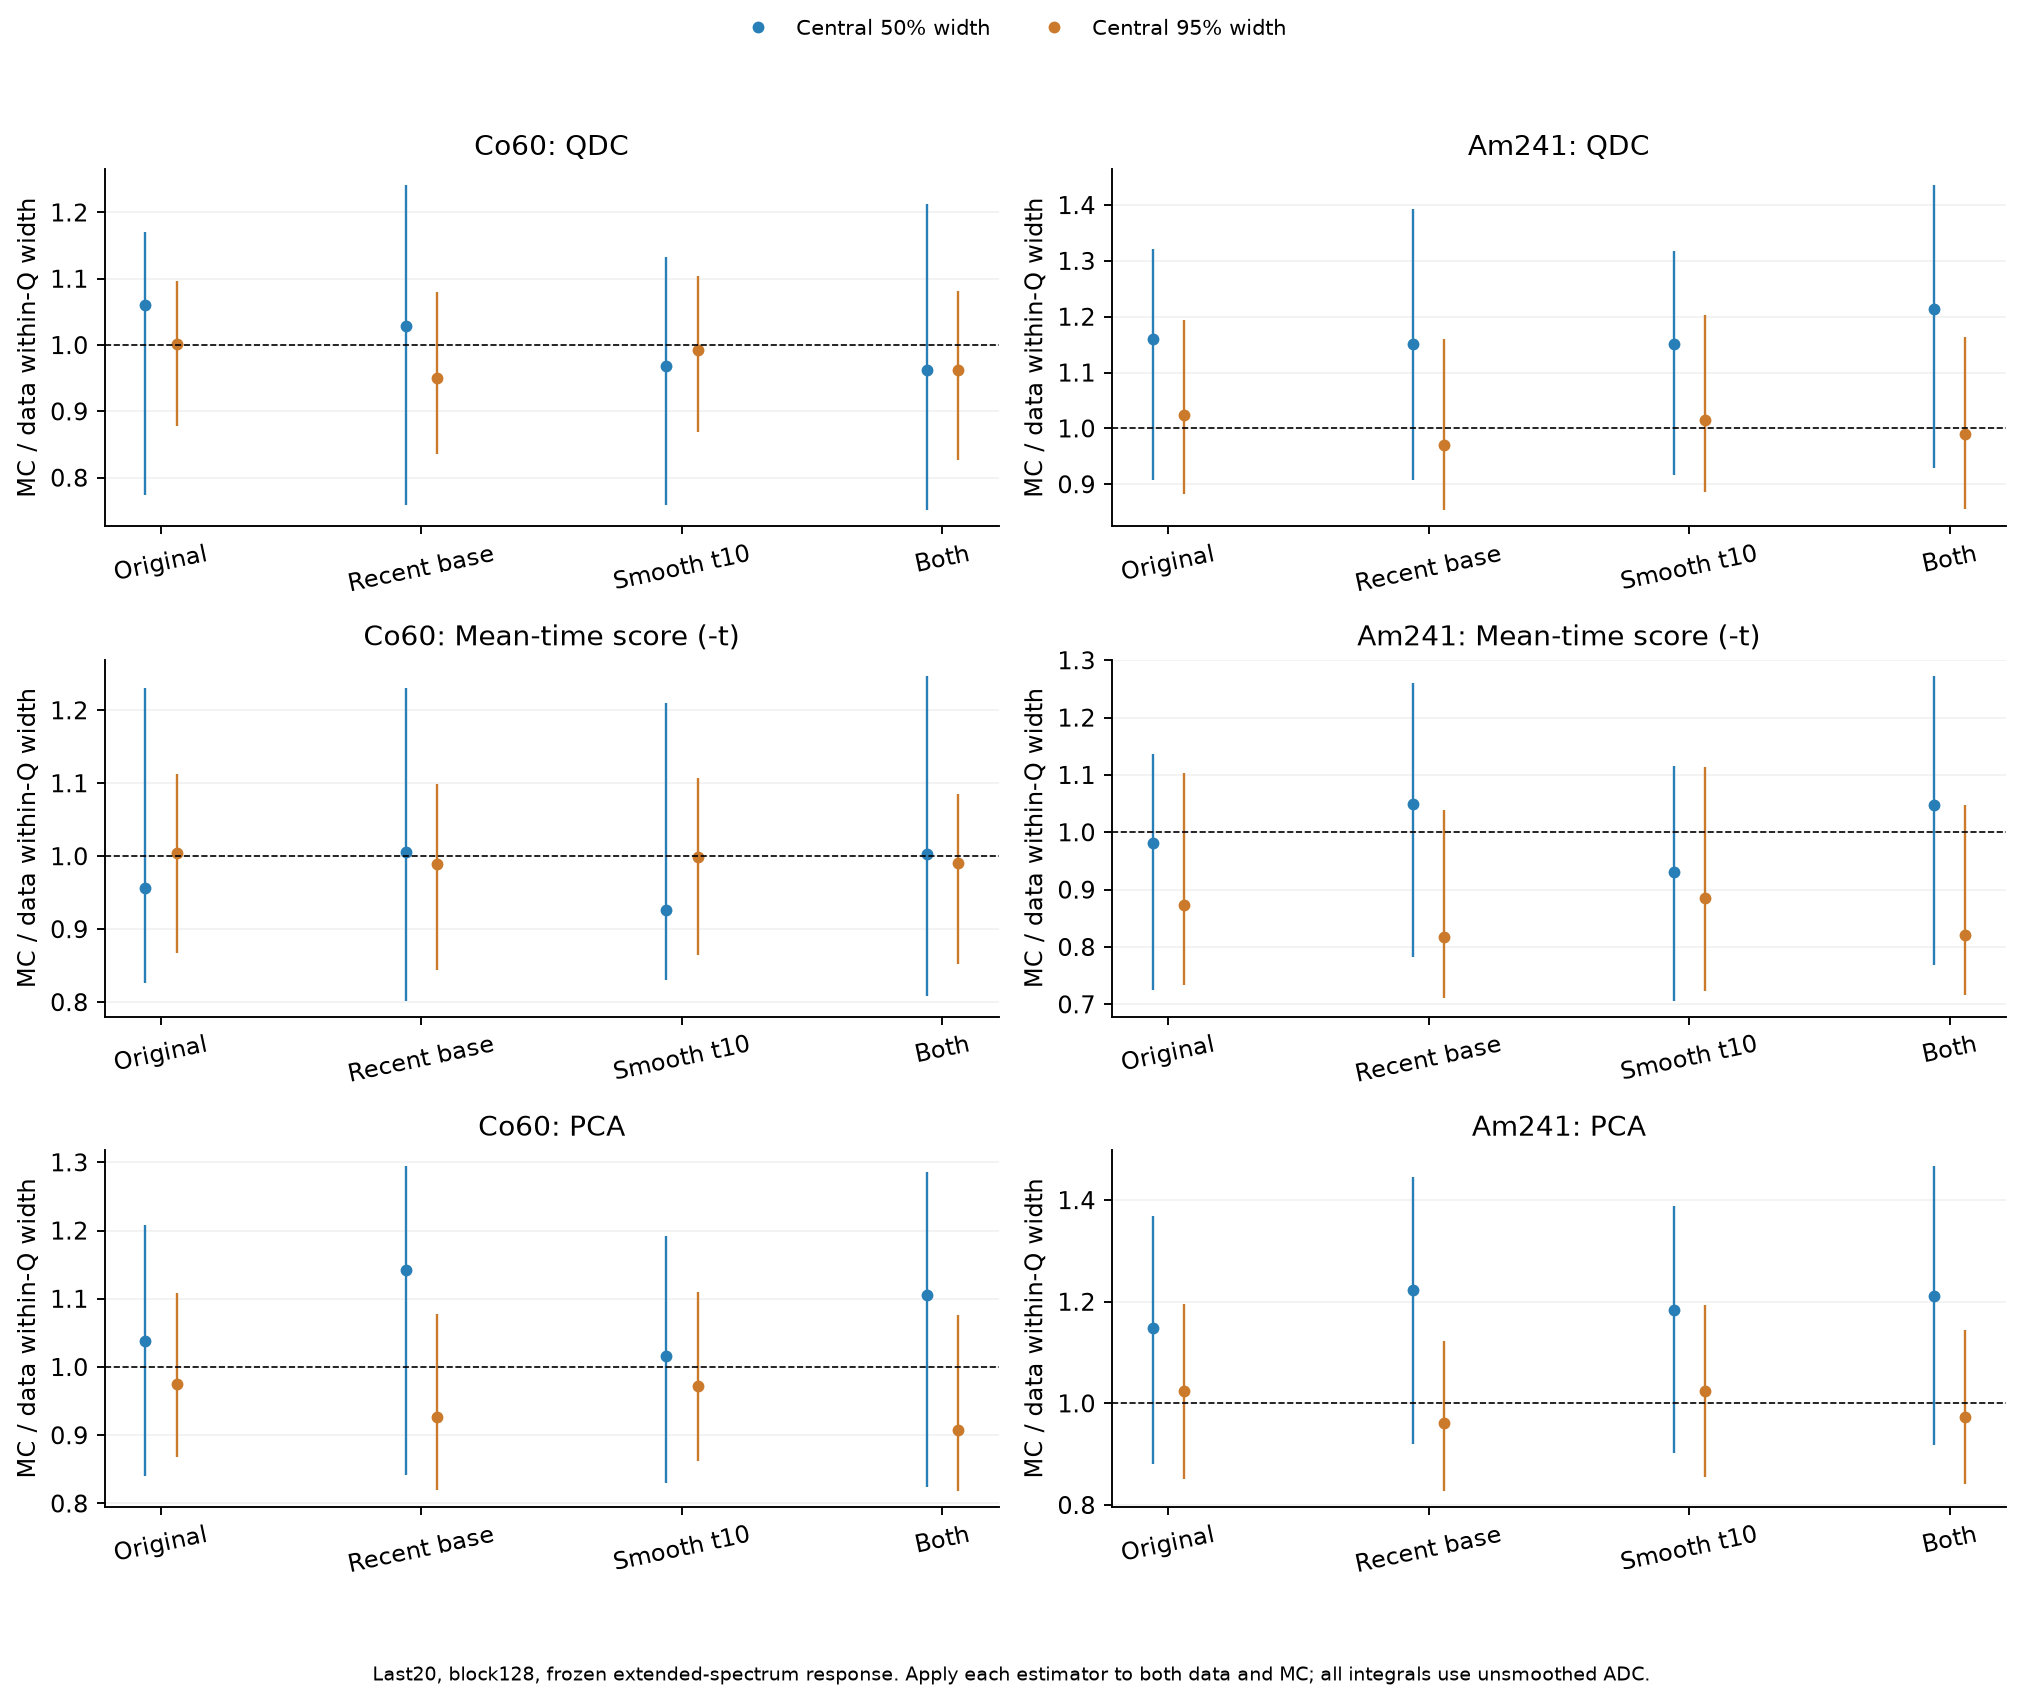

In [4]:
rows=[]
for key in ['run3_last20','run12_last20']:
    for B in ['128','64']:
        controls=e['groups'][key][B]['variants']['spectrum_CV_fit']['controls']
        for name,r in controls.items():
            rows.append([key,B,control_labels[name],fmt(r['point'][metric]),ci(r['CI95'][metric]),ci(r['paired_from_original'][metric])])
display(Markdown(table(['晚段','块长','定义','平均时间95%宽度MC/实测','条件95%区间','相对原定义配对变化区间'],rows)))
display(Image(filename=str(OUT/'figures/tail_estimator_width_controls.png')))

In [5]:
rows=[]
for key,blocks in e['groups'].items():
    for variant,r in blocks['128']['variants'].items():
        c=r['controls']
        rows.append([key,model_labels[variant],*[fmt(c[name]['point'][metric]) for name in p['controls']]])
display(Markdown(table(['组','固定模型','原定义','近期基线','平滑定位','二者同时'],rows)))
display(Markdown('Am晚段的二者同时对照由0.872变为0.822，配对变化区间包含0；前段和中段变化方向不同。当前没有依据采用统一修正。其他得分、50/80/90%宽度及SD均保留在144行control_table.csv和analysis.json中。'))

|组|固定模型|原定义|近期基线|平滑定位|二者同时|
|---|---|---|---|---|---|
|run3_first60|原冻结|0.903|0.935|0.923|0.954|
|run3_first60|连续RC+原谱/CV|0.907|0.938|0.925|0.960|
|run3_first60|连续RC+扩展谱/CV|0.953|0.981|0.965|0.998|
|run3_middle20|原冻结|0.962|0.923|0.983|0.930|
|run3_middle20|连续RC+原谱/CV|0.959|0.920|0.987|0.934|
|run3_middle20|连续RC+扩展谱/CV|0.945|0.909|0.973|0.924|
|run3_last20|原冻结|0.973|0.968|0.968|0.958|
|run3_last20|连续RC+原谱/CV|0.968|0.968|0.969|0.963|
|run3_last20|连续RC+扩展谱/CV|1.004|0.989|1.000|0.990|
|run12_first60|原冻结|0.909|0.943|0.921|0.955|
|run12_first60|连续RC+原谱/CV|0.899|0.934|0.913|0.954|
|run12_first60|连续RC+扩展谱/CV|0.896|0.931|0.910|0.951|
|run12_middle20|原冻结|0.825|0.914|0.835|0.922|
|run12_middle20|连续RC+原谱/CV|0.864|0.913|0.865|0.921|
|run12_middle20|连续RC+扩展谱/CV|0.898|0.956|0.899|0.962|
|run12_last20|原冻结|0.776|0.767|0.793|0.773|
|run12_last20|连续RC+原谱/CV|0.822|0.773|0.831|0.774|
|run12_last20|连续RC+扩展谱/CV|0.872|0.817|0.885|0.822|

Am晚段的二者同时对照由0.872变为0.822，配对变化区间包含0；前段和中段变化方向不同。当前没有依据采用统一修正。其他得分、50/80/90%宽度及SD均保留在144行control_table.csv和analysis.json中。

## 3. 尾部事件的可观察特征

沿用上一轮的联合PID尾部：三个原得分中任一`|z|>2`，其中稳健尺度由对折实验的中位数和IQR定义。
新观察量包括近期与前128点基线差、前256点斜率、整数锚点/分数t₁₀变化、500–1500和2000–3000 ns电荷份额。
基线差除以前128点RMS，**不是标准误或显著性z值**。
“后段正向台阶”是600–2800 ns间相邻40 ns平均ADC的最大正向差除原峰幅；它不是堆积分类器。

每Q箱/评价折仅用对折实验估计四个描述标记：绝对基线差/RMS的99%分位、绝对整数锚点差的99%分位、后段正台阶的99%分位、晚电荷份额的1%–99%边界。
同一边界应用于实验/MC，不做删选。标记可能重叠，未触发高分位标记也不能排除较弱效应。


|组|来源|原支持事件数|联合尾部数|基线/锚点/台阶/晚份额标记数|尾部未触发任何标记数|
|---|---|---|---|---|---|
|run3_first60|实测|2423|189|[3, 0, 3, 30]|154|
|run3_first60|扩展谱MC|276|29|[0, 0, 0, 3]|26|
|run3_middle20|实测|843|121|[7, 1, 7, 26]|82|
|run3_middle20|扩展谱MC|276|79|[1, 0, 1, 14]|65|
|run3_last20|实测|821|100|[2, 1, 4, 16]|78|
|run3_last20|扩展谱MC|276|44|[0, 0, 0, 5]|39|
|run12_first60|实测|1178|97|[3, 0, 7, 17]|74|
|run12_first60|扩展谱MC|180|18|[0, 1, 0, 1]|16|
|run12_middle20|实测|353|44|[1, 1, 1, 8]|34|
|run12_middle20|扩展谱MC|180|27|[0, 0, 0, 2]|25|
|run12_last20|实测|316|30|[0, 1, 0, 10]|20|
|run12_last20|扩展谱MC|180|18|[0, 0, 1, 1]|16|

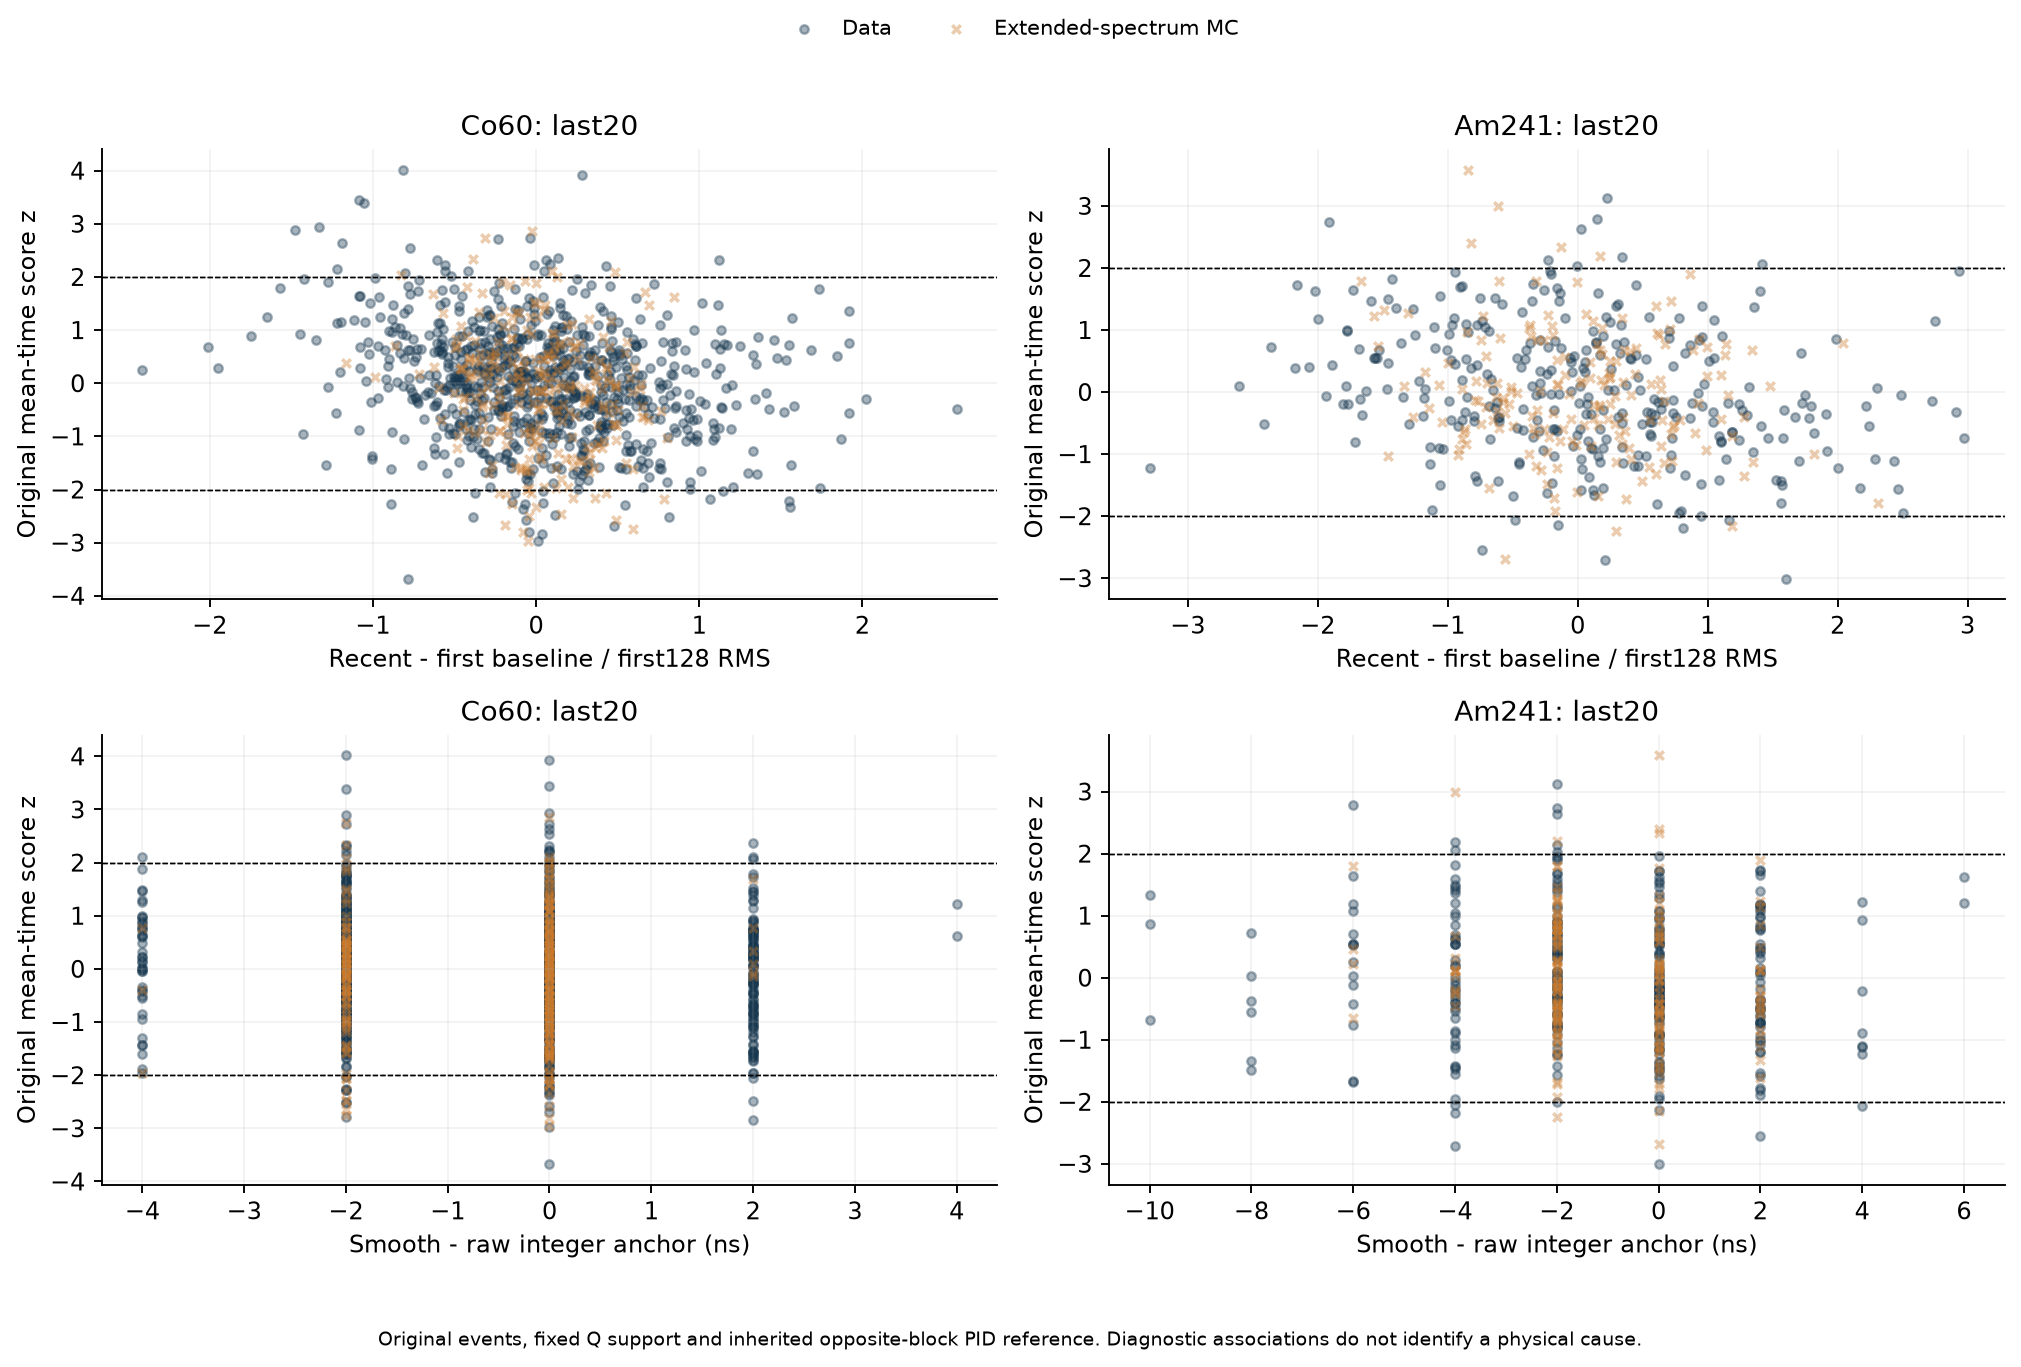

Am晚段30条实验联合尾部中，20条未触发上述任一标记；MC为18条中16条。不能把剩余宽度差异简单归为这些标记对应的坏事件，更不能据此删除尾部。

In [6]:
rows=[]
for key,blocks in e['groups'].items():
    for variant in ['data','spectrum_CV_fit']:
        a=blocks['128']['feature_audits'][variant]
        rows.append([key,'实测' if variant=='data' else '扩展谱MC',a['support_events'],a['joint_PID_tail_events'],a['flag_events_in_PID_tail'],a['PID_tail_events_without_any_flag']])
display(Markdown(table(['组','来源','原支持事件数','联合尾部数','基线/锚点/台阶/晚份额标记数','尾部未触发任何标记数'],rows)))
display(Image(filename=str(OUT/'figures/tail_baseline_anchor_observables.png')))
display(Markdown('Am晚段30条实验联合尾部中，20条未触发上述任一标记；MC为18条中16条。不能把剩余宽度差异简单归为这些标记对应的坏事件，更不能据此删除尾部。'))

## 4. 固定三维波形子空间

将原门内76个40 ns电荷份额作为形状向量，每事件各份额之和为1。
每折仅用对折实验的箱内协方差训练，预先固定取前三个特征向量；最大绝对系数取正号。
同一组向量用于相应实验/MC检查折。模式只用于诊断，没有合成ADC、注入实测模板或修改PID得分。

方差在每个检查Q箱/折内以该组自己的均值居中，保留该折的原权重质量。正交投影满足：
`完整形状方差 = 三模式内方差 + 正交剩余方差`。
另存检查均值相对训练模板的平方偏差，不把这项偏差混入随机方差。
模式可在两折间旋转；`svd(U₀ᵀU₁)`给出两个三维子空间的主角余弦，最小值描述最弱的共同方向，不能唯一对应排序中的第三特征向量。


|晚段|两训练折三维解释份额/%|实测检查份额/%|MC检查份额/%|两折子空间奇异值|
|---|---|---|---|---|
|run3_last20|45.697 / 46.850|41.736|43.189|0.983 / 0.953 / 0.714|
|run12_last20|38.189 / 34.911|32.388|33.312|0.981 / 0.916 / 0.608|

|Am晚段块长|指标（最后项为百分点差，其余为比）|点估计|条件95%区间|
|---|---|---|---|
|128|PC1_variance_ratio|1.162|[0.917, 1.427]|
|128|PC2_variance_ratio|0.913|[0.727, 1.116]|
|128|PC3_variance_ratio|0.991|[0.742, 1.238]|
|128|rank3_variance_ratio|1.044|[0.900, 1.161]|
|128|orthogonal_variance_ratio|1.001|[0.916, 1.045]|
|128|full_shape_variance_ratio|1.015|[0.933, 1.052]|
|128|rank3_fraction_delta_pp|0.924|[-2.136, 4.191]|
|64|PC1_variance_ratio|1.161|[0.908, 1.430]|
|64|PC2_variance_ratio|1.013|[0.805, 1.241]|
|64|PC3_variance_ratio|0.954|[0.734, 1.253]|
|64|rank3_variance_ratio|1.069|[0.913, 1.244]|
|64|orthogonal_variance_ratio|0.982|[0.907, 1.029]|
|64|full_shape_variance_ratio|1.010|[0.939, 1.066]|
|64|rank3_fraction_delta_pp|1.870|[-1.679, 5.902]|

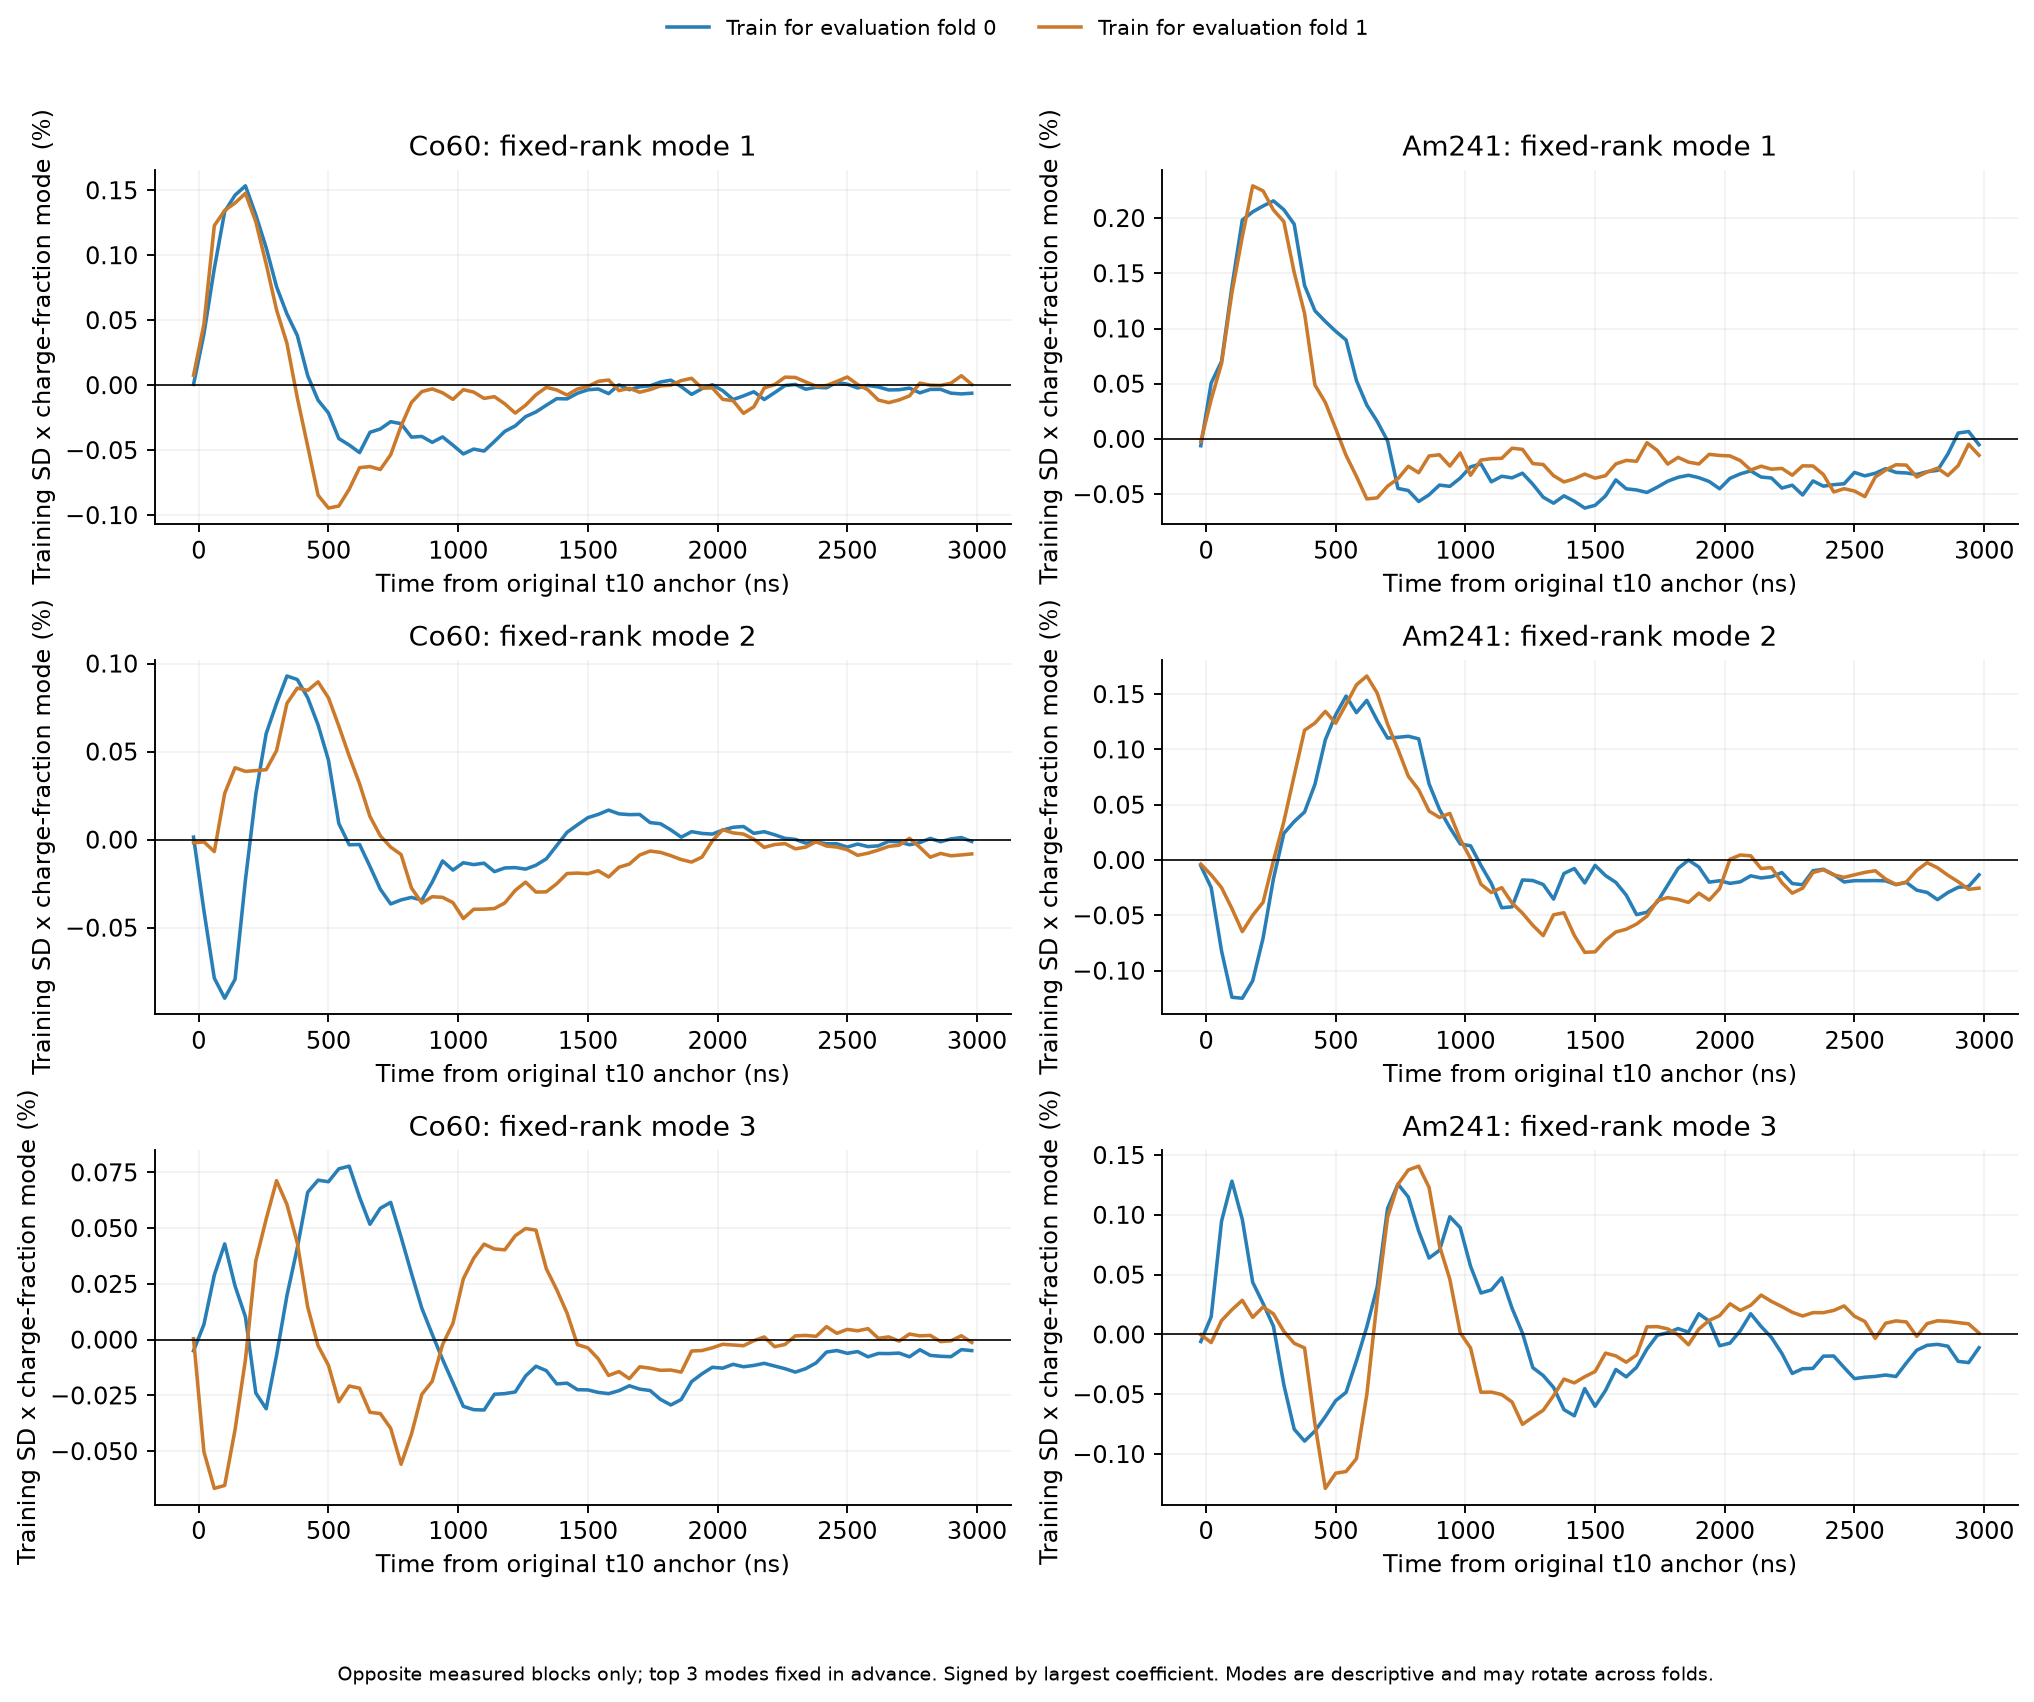

Am晚段前三模式仅覆盖约三分之一检查方差。三维、正交剩余及完整方差比分别约1.044、1.001、1.015，区间均包含1；这不是高阶分布已一致的证明。两折最小子空间奇异值约0.608，当前不能将三个统计方向解释为已识别的物理噪声分量。

In [7]:
rows=[]
for key in ['run3_last20','run12_last20']:
    g=e['groups'][key]['128'];m=g['variants']['spectrum_CV_fit']
    rows.append([key,nums(100*np.array(g['training_rank3_fractions'])),fmt(100*g['data_modes']['captured_fraction']),fmt(100*m['native_modes']['captured_fraction']),nums(g['fold_subspace_singular_values'])])
display(Markdown(table(['晚段','两训练折三维解释份额/%','实测检查份额/%','MC检查份额/%','两折子空间奇异值'],rows)))
rows=[]
for B in ['128','64']:
    m=e['groups']['run12_last20'][B]['variants']['spectrum_CV_fit']
    for name,point in m['mode_point'].items():
        rows.append([B,name,fmt(point),ci(m['mode_CI95'][name])])
display(Markdown(table(['Am晚段块长','指标（最后项为百分点差，其余为比）','点估计','条件95%区间'],rows)))
display(Image(filename=str(OUT/'figures/trained_waveform_modes.png')))
display(Markdown('Am晚段前三模式仅覆盖约三分之一检查方差。三维、正交剩余及完整方差比分别约1.044、1.001、1.015，区间均包含1；这不是高阶分布已一致的证明。两折最小子空间奇异值约0.608，当前不能将三个统计方向解释为已识别的物理噪声分量。'))

## 5. 判断、下一步与复现


In [8]:
display(Markdown(decision['conclusion_zh']))
display(Markdown(decision['next_work_zh']))
for limit in decision['limitations_zh']:display(Markdown('边界：'+limit))
print('默认配置 / 正式PID已替换:',decision['default_changed'],decision['official_PID_changed'])
print('计算: prepare_waveform_tail.py → analyze_waveform_tail.py → plot_waveform_tail.py → summarize_waveform_tail.py')
print('笔记: jupyter/codex_0001_build_waveform_tail_notebook.py')
print('核验: simulation/verify_waveform_tail.py；封存: 同脚本 --archive')
print('结果目录:',OUT)

默认配置 / 正式PID已替换: False False
计算: prepare_waveform_tail.py → analyze_waveform_tail.py → plot_waveform_tail.py → summarize_waveform_tail.py
笔记: jupyter/codex_0001_build_waveform_tail_notebook.py
核验: simulation/verify_waveform_tail.py；封存: 同脚本 --archive
结果目录: /media/sf_works/SiPM/simulation/results/waveform_tail_20261030


本轮完成原始ADC极端分位示例、四种基线/取时对照及固定三维波形模式诊断。Am晚段扩展谱（块128）的平均时间95%分位宽度比，原定义为0.872，近期基线与平滑取时同时应用后为0.822；配对变化95%区间为[-0.161, 0.082]，包含0。该统一修正没有解决晚段外侧宽度差异，正式PID和默认模拟参数保持原样。

下一步应冻结现有候选和评价定义，先增加独立种子的Geant4母事件，检查当前仅180个受支持Am母事件导致的分位宽度和模式估计波动。该轮应明确标成模拟统计复现/诊断，保留原模型与两种固定响应，不把新增模拟当成新实验或最终验证；新批次结果不得再用于调整同一批次的参数。若独立批次重复出现同方向的核心/外侧差异，再针对稳定波形方向提出受约束的非高斯事件间变化，并同时检验均ADC、分位宽度、完整协方差和F。

边界：全部实验已探索；对折仅隔离本轮模式与标记阈值，既有响应、PCA与Q目标含先前校准信息。

边界：512次区间固定响应参数、模式、诊断边界和目标权重，未含这些量的拟合不确定度或多重比较校正；未作等效性检验。

边界：前触发和信号观察量不是因果分类器，后段正台阶不等于堆积，未触发标记不等于无任何异常。

边界：波形模式以每事件Q归一化并含噪声/定位影响，二阶量不能唯一识别闪烁、SiPM或读出机制；模式符号与序号不保证跨折相同物理方向。

边界：所示示例只是固定规则下的有限事件，不代表粒子真值、粒子效率或整体一致性；Am实验主带仍不能当作纯α。

本轮冻结协议`protocol.json`先于新数值结果保存；`designs/`保留训练/检查ID、基准形状、阈值和特征向量。
`examples.json`及`example_events.csv`保存36条选取记录，`arrays/`保存控制得分及原ADC示例；`control_table.csv`含144行对照，`analysis.json`保留所有组和区间，`bootstrap.npz`保留配对抽样。
核验包括原BIN逐事件一致、四种定义的独立前缀和积分重算、对折隔离、特征分解与直接协方差分解、原宽度/SD点估计及区间沿用、示例规则和原ADC、执行笔记及5幅嵌入图一致。
`verification.json`及`record.json`保存结果、输入和源码哈希。完整复跑需使用新结果目录；不要覆盖已封存记录。本轮未检索文献或修改共享文献库。
